# Financial Time Series Analytics

## Reproducible data collection and currency standardisation

Research window: 2 January 2015 to 24 August 2026 (inclusive). Raw OHLC prices are downloaded without auto-adjustment. Goldman Sachs USD prices are converted to GBX using a strictly prior available GBP/USD close; Lloyds and Barclays remain in GBX. The notebook validates dates, exchange rates, conversion arithmetic, duplicate bank-date records and OHLC consistency before exporting the common modelling dataset.


## Data Scrapping

### Installing requireds Packages

In [1]:
!pip install yfinance pandas

## Scrapping banks Data seperately

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np

RESEARCH_START = "2015-01-02"
RESEARCH_END_EXCLUSIVE = "2026-08-25"
RESEARCH_END = pd.Timestamp("2026-08-24")

def extract_yfinance_ohlcv(raw, ticker, bank_name):
    """Normalise yfinance single- or multi-level columns to OHLCV fields."""
    if raw is None or raw.empty:
        raise ValueError(f"No price data returned for {ticker} ({bank_name}).")

    required = ["Open", "High", "Low", "Close", "Volume"]
    if isinstance(raw.columns, pd.MultiIndex):
        extracted = {}
        for field in required:
            matches = [col for col in raw.columns if field in [str(x) for x in col]]
            if not matches:
                raise KeyError(f"{field} not found for {ticker}. Columns: {raw.columns}")
            extracted[field] = raw.loc[:, matches[0]]
        result = pd.DataFrame(extracted, index=raw.index)
    else:
        missing = [field for field in required if field not in raw.columns]
        if missing:
            raise KeyError(f"Missing {missing} for {ticker}. Columns: {raw.columns}")
        result = raw[required].copy()

    result.index.name = "Date"
    result["Bank"] = bank_name
    return result

download_options = {
    "start": RESEARCH_START,
    "end": RESEARCH_END_EXCLUSIVE,
    "auto_adjust": False,
    "actions": False,
    "progress": False,
    "threads": False,
}

lloyds_raw = yf.download("LLOY.L", **download_options)
barclays_raw = yf.download("BARC.L", **download_options)
gs_raw = yf.download("GS", **download_options)

lloyds = extract_yfinance_ohlcv(lloyds_raw, "LLOY.L", "Lloyds")
barclays = extract_yfinance_ohlcv(barclays_raw, "BARC.L", "Barclays")
gs = extract_yfinance_ohlcv(gs_raw, "GS", "Goldman Sachs")

print("Download settings:", download_options)
for bank_name, frame in [
    ("Lloyds", lloyds), ("Barclays", barclays), ("Goldman Sachs", gs)
]:
    print(
        f"{bank_name}: rows={len(frame):,}; "
        f"range={frame.index.min().date()} to {frame.index.max().date()}"
    )


Download settings: {'start': '2015-01-02', 'end': '2026-08-25', 'auto_adjust': False, 'actions': False, 'progress': False, 'threads': False}
Lloyds: rows=2,942; range=2015-01-02 to 2026-08-24
Barclays: rows=2,941; range=2015-01-02 to 2026-08-24
Goldman Sachs: rows=2,927; range=2015-01-02 to 2026-08-24


## Verify each share's native quotation currency

This section records the currency reported in Yahoo Finance instrument metadata for each exact ticker used in this study. Yahoo may label UK pence as GBp; this is the same pence-sterling denomination represented as GBX in the modelling dataset. The code checks the reported currency against the expected listing currency before any conversion is performed. This metadata check is evidence of the instrument's quote currency.


In [3]:
ticker_currency_expectations = {
    "LLOY.L": {"bank": "Lloyds", "expected_currency": "GBp", "accepted": {"GBp", "GBX"}},
    "BARC.L": {"bank": "Barclays", "expected_currency": "GBp", "accepted": {"GBp", "GBX"}},
    "GS": {"bank": "Goldman Sachs", "expected_currency": "USD", "accepted": {"USD"}},
}

currency_evidence_rows = []
for ticker, expectation in ticker_currency_expectations.items():
    info = yf.Ticker(ticker).get_info()
    reported_currency = info.get("currency")
    exchange = info.get("exchange")
    full_exchange_name = info.get("fullExchangeName")
    short_name = info.get("shortName")
    long_name = info.get("longName")

    if not reported_currency:
        raise ValueError(
            f"Yahoo Finance did not return currency metadata for {ticker}. "
            "Do not assume the currency; investigate the instrument metadata."
        )

    if reported_currency not in expectation["accepted"]:
        raise AssertionError(
            f"{ticker} ({expectation['bank']}): expected {expectation['accepted']}, "
            f"but Yahoo Finance reports {reported_currency!r}."
        )

    currency_evidence_rows.append({
        "Bank": expectation["bank"],
        "Ticker": ticker,
        "Reported_Yahoo_Currency": reported_currency,
        "Interpretation": (
            "GBX (pence sterling; Yahoo label GBp)"
            if reported_currency in {"GBp", "GBX"} else "USD"
        ),
        "Exchange_Code": exchange,
        "Exchange_Name": full_exchange_name,
        "Instrument_Name": long_name or short_name,
        "Metadata_Source": "Yahoo Finance instrument metadata via yfinance Ticker.get_info()",
    })

currency_evidence = pd.DataFrame(currency_evidence_rows)
display(currency_evidence)

print("\nNATIVE CURRENCY VERIFICATION")
for _, row in currency_evidence.iterrows():
    print(
        f"{row['Bank']} ({row['Ticker']}): Yahoo reports "
        f"{row['Reported_Yahoo_Currency']} -> {row['Interpretation']}"
    )

assert currency_evidence.loc[
    currency_evidence["Ticker"].isin(["LLOY.L", "BARC.L"]),
    "Reported_Yahoo_Currency"
].isin(["GBp", "GBX"]).all()
assert currency_evidence.loc[
    currency_evidence["Ticker"].eq("GS"),
    "Reported_Yahoo_Currency"
].eq("USD").all()

currency_evidence.to_csv("native_currency_metadata_evidence.csv", index=False)
print("\nCurrency metadata checks passed. Evidence saved to native_currency_metadata_evidence.csv.")


,Bank,Ticker,Reported_Yahoo_Currency,Interpretation,Exchange_Code,Exchange_Name,Instrument_Name,Metadata_Source
0,Lloyds,LLOY.L,GBp,GBX (pence sterling; Yahoo label GBp),LSE,LSE,Lloyds Banking Group plc,Yahoo Finance instrument metadata via yfinance...
1,Barclays,BARC.L,GBp,GBX (pence sterling; Yahoo label GBp),LSE,LSE,Barclays PLC,Yahoo Finance instrument metadata via yfinance...
2,Goldman Sachs,GS,USD,USD,NYQ,NYSE,"The Goldman Sachs Group, Inc.",Yahoo Finance instrument metadata via yfinance...



NATIVE CURRENCY VERIFICATION
Lloyds (LLOY.L): Yahoo reports GBp -> GBX (pence sterling; Yahoo label GBp)
Barclays (BARC.L): Yahoo reports GBp -> GBX (pence sterling; Yahoo label GBp)
Goldman Sachs (GS): Yahoo reports USD -> USD

Currency metadata checks passed. Evidence saved to native_currency_metadata_evidence.csv.


In [4]:
lloyds.reset_index(inplace=True)
barclays.reset_index(inplace=True)
gs.reset_index(inplace=True)

In [5]:
final_df = pd.concat(
    [lloyds, barclays, gs],
    ignore_index=True
)

### Inspecting LLoyds Bank Data

In [6]:
lloyds.to_csv(
    "lloyds_bank_stock_data.csv",
    index=False
)

print("Dataset saved successfully!")
print(lloyds.head())
print(f"Total rows: {len(lloyds)}")

Dataset saved successfully!
        Date       Open       High        Low      Close     Volume    Bank
0 2015-01-02  76.470001  76.750000  75.668999  76.150002   54277932  Lloyds
1 2015-01-05  76.070000  76.400002  74.459999  74.620003  102525515  Lloyds
2 2015-01-06  74.629997  75.050003  72.870003  72.870003  133810250  Lloyds
3 2015-01-07  73.320000  73.943001  72.870003  73.010002  108980419  Lloyds
4 2015-01-08  73.510002  74.419998  73.250000  74.099998   79367070  Lloyds
Total rows: 2942


### Inspecting barclays Bank Data

In [7]:
barclays.to_csv(
    "barclays_bank_stock_data.csv",
    index=False
)

print("Dataset saved successfully!")
print(barclays.head())
print(f"Total rows: {len(barclays)}")

Dataset saved successfully!
        Date        Open        High         Low       Close    Volume  \
0 2015-01-02  242.199997  245.600006  241.550003  243.149994  20219711   
1 2015-01-05  242.300003  243.149994  234.199997  234.699997  39050852   
2 2015-01-06  234.050003  235.850006  230.250000  230.350006  37573308   
3 2015-01-07  232.100006  233.460007  230.149994  230.600006  37219841   
4 2015-01-08  234.300003  238.350006  231.550003  237.050003  41082776   

       Bank  
0  Barclays  
1  Barclays  
2  Barclays  
3  Barclays  
4  Barclays  
Total rows: 2941


### Inspecting Goldman Sachs Bank Data

In [8]:
gs.to_csv(
    "gs_bank_stock_data.csv",
    index=False
)

print("Dataset saved successfully!")
print(gs.head())
print(f"Total rows: {len(gs)}")

Dataset saved successfully!
        Date        Open        High         Low       Close   Volume  \
0 2015-01-02  195.300003  195.729996  192.699997  194.410004  1877700   
1 2015-01-05  193.059998  194.039993  187.479996  188.339996  3413200   
2 2015-01-06  188.300003  188.660004  183.929993  184.529999  3429200   
3 2015-01-07  186.850006  187.990005  185.770004  187.279999  1896800   
4 2015-01-08  189.350006  190.820007  189.250000  190.270004  1962500   

            Bank  
0  Goldman Sachs  
1  Goldman Sachs  
2  Goldman Sachs  
3  Goldman Sachs  
4  Goldman Sachs  
Total rows: 2927


## Importing all 3 data files

In [9]:
import pandas as pd

lloyds = pd.read_csv("lloyds_bank_stock_data.csv")
barclays = pd.read_csv("barclays_bank_stock_data.csv")
gs = pd.read_csv("gs_bank_stock_data.csv")

In [10]:
print(lloyds.columns)
print(barclays.columns)
print(gs.columns)

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Bank'], dtype='object')
Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Bank'], dtype='object')
Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Bank'], dtype='object')


## Reordering Coloumns

In [11]:
lloyds = lloyds[
    ['Date', 'Bank', 'Open', 'High', 'Low', 'Close', 'Volume']
]

barclays = barclays[
    ['Date', 'Bank', 'Open', 'High', 'Low', 'Close', 'Volume']
]

gs = gs[
    ['Date', 'Bank', 'Open', 'High', 'Low', 'Close', 'Volume']
]

In [12]:
print(lloyds.columns)
print(barclays.columns)
print(gs.columns)

Index(['Date', 'Bank', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='object')
Index(['Date', 'Bank', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='object')
Index(['Date', 'Bank', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='object')


## Merging all the 3 banks datasets


In [13]:
all_banks = pd.concat(
    [lloyds, barclays, gs],
    ignore_index=True
)

In [14]:
print(all_banks.head())

print(all_banks.shape)

print(all_banks['Bank'].value_counts())

         Date    Bank       Open       High        Low      Close     Volume
0  2015-01-02  Lloyds  76.470001  76.750000  75.668999  76.150002   54277932
1  2015-01-05  Lloyds  76.070000  76.400002  74.459999  74.620003  102525515
2  2015-01-06  Lloyds  74.629997  75.050003  72.870003  72.870003  133810250
3  2015-01-07  Lloyds  73.320000  73.943001  72.870003  73.010002  108980419
4  2015-01-08  Lloyds  73.510002  74.419998  73.250000  74.099998   79367070
(8810, 7)
Bank
Lloyds           2942
Barclays         2941
Goldman Sachs    2927
Name: count, dtype: int64


## Downloading The file dataset file

In [15]:
all_banks.to_csv(
    'all_bank_stock_data.csv',
    index=False
)

## Dataset Cleaning

### Identify the Bad Rows

In [16]:
import pandas as pd

df = pd.read_csv("all_bank_stock_data.csv")

In [17]:
df[df['Date'].isna()]

,Date,Bank,Open,High,Low,Close,Volume


## Removing bad rows

In [18]:
df = df.dropna(
    subset=['Date']
)

### Verifing

In [19]:
df[df['Date'].isna()]

,Date,Bank,Open,High,Low,Close,Volume


In [20]:
print(df.shape)

(8810, 7)


## Converting date to datetime

In [21]:
df['Date'] = pd.to_datetime(df['Date'])

### verify

In [22]:
print(df.dtypes)

Date      datetime64[ns]
Bank              object
Open             float64
High             float64
Low              float64
Close            float64
Volume             int64
dtype: object


### Convert Numeric Columns

In [23]:
numeric_cols = [
    'Open',
    'High',
    'Low',
    'Close',
    'Volume'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col])

In [24]:
print(df.dtypes)

Date      datetime64[ns]
Bank              object
Open             float64
High             float64
Low              float64
Close            float64
Volume             int64
dtype: object


### Currency standardisation (USD to GBX)

 Lloyds (LLOY.L) and Barclays (BARC.L) are London-listed shares quoted in GBX (pence), so their OHLC prices are retained unchanged. Goldman Sachs (GS) is a New York-listed share quoted in USD. For cross-bank comparisons and the pooled modelling dataset, its Open, High, Low and Close prices are converted to GBX.

The Yahoo Finance `GBPUSD=X` quote is USD per GBP. Therefore:

`Goldman price (GBX) = Goldman price (USD) / GBPUSD × 100`

The conversion uses the latest available FX close strictly before the stock trading date allow_exact_matches=False. This conservative lag avoids using an FX daily close that may have been recorded after the stock market's closing time. The matched FX date and age are retained for audit. A maximum seven-calendar-day gap is allowed to accommodate weekends and extended market holidays, unmatched or stale rates stop the notebook rather than being filled from future observations.

Trading volume is a share count, not a currency amount, and is therefore not converted. Native USD price columns are retained alongside the standardised GBX columns for traceability.


In [25]:
df_original = df.copy()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
if df["Date"].isna().any():
    raise ValueError("Invalid stock dates remain before FX matching.")

def strip_timezone_preserve_date(values):
    dates = pd.to_datetime(values, errors="coerce")
    if getattr(dates.dt, "tz", None) is not None:
        dates = dates.dt.tz_localize(None)
    return dates.dt.normalize()

df["Date"] = strip_timezone_preserve_date(df["Date"])
df = df.loc[df["Date"].between(
    pd.Timestamp(RESEARCH_START), RESEARCH_END, inclusive="both"
)].copy()
df = df.sort_values(["Date", "Bank"]).reset_index(drop=True)

fx_start = (df["Date"].min() - pd.Timedelta(days=10)).strftime("%Y-%m-%d")
fx_end = (df["Date"].max() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
fx_raw = yf.download(
    "GBPUSD=X",
    start=fx_start,
    end=fx_end,
    auto_adjust=False,
    actions=False,
    progress=False,
    threads=False,
)

if fx_raw.empty:
    raise ValueError("No GBP/USD exchange-rate data was downloaded.")

if isinstance(fx_raw.columns, pd.MultiIndex):
    fx_matches = [
        col for col in fx_raw.columns
        if "Close" in [str(part) for part in col]
    ]
    if not fx_matches:
        raise KeyError("Close column not found in GBP/USD MultiIndex data.")
    fx_close = fx_raw.loc[:, fx_matches[0]]
else:
    if "Close" not in fx_raw.columns:
        raise KeyError("Close column not found in GBP/USD data.")
    fx_close = fx_raw["Close"]

fx = fx_close.rename("GBPUSD").to_frame().reset_index()
fx = fx.rename(columns={fx.columns[0]: "FX_Date"})
fx["FX_Date"] = strip_timezone_preserve_date(fx["FX_Date"])
fx["GBPUSD"] = pd.to_numeric(fx["GBPUSD"], errors="coerce")
fx = (
    fx.dropna(subset=["FX_Date", "GBPUSD"])
      .drop_duplicates(subset=["FX_Date"], keep="last")
      .sort_values("FX_Date")
      .reset_index(drop=True)
)

if fx.empty or (fx["GBPUSD"] <= 0).any():
    raise ValueError("GBP/USD series is empty or contains non-positive rates.")

MAX_FX_AGE_DAYS = 7

df = pd.merge_asof(
    df.sort_values("Date"),
    fx.sort_values("FX_Date"),
    left_on="Date",
    right_on="FX_Date",
    direction="backward",
    allow_exact_matches=False,
    tolerance=pd.Timedelta(days=MAX_FX_AGE_DAYS),
)

df["FX_Age_Days"] = (df["Date"] - df["FX_Date"]).dt.days
if df["GBPUSD"].isna().any():
    examples = df.loc[
        df["GBPUSD"].isna(), ["Date", "Bank"]
    ].head(10)
    raise ValueError(
        f"{df['GBPUSD'].isna().sum()} rows have no strictly prior GBP/USD rate. "
        f"Examples:\\n{examples}"
    )

if not (df["FX_Date"] < df["Date"]).all():
    raise AssertionError("FX matching used same-day or future FX observations.")
if (df["FX_Age_Days"] > MAX_FX_AGE_DAYS).any():
    raise AssertionError("An FX observation older than seven calendar days was used.")


df_before_conversion = df.copy()
usd_mask = df_before_conversion["Bank"].eq("Goldman Sachs")
native_ohlc = ["Open", "High", "Low", "Close"]


for col in native_ohlc:
    gbx_col = f"{col}_GBX"
    df[gbx_col] = pd.to_numeric(df_before_conversion[col], errors="coerce")
    df.loc[usd_mask, gbx_col] = (
        pd.to_numeric(df_before_conversion.loc[usd_mask, col], errors="coerce")
        / df_before_conversion.loc[usd_mask, "GBPUSD"]
    ) * 100.0

df["Native_Currency"] = np.where(usd_mask, "USD", "GBX")
df["Price_Currency"] = "GBX"

print("FX quote: GBPUSD=X (USD per GBP)")
print("Conversion: USD / GBPUSD * 100 = GBX")
print(f"FX matching: strictly prior observation; maximum age {MAX_FX_AGE_DAYS} calendar days")
print("FX observations downloaded:", len(fx))
print("Goldman Sachs rows converted:", int(usd_mask.sum()))
print("Maximum FX age (days):", int(df["FX_Age_Days"].max()))
print("Research period:", df["Date"].min().date(), "to", df["Date"].max().date())
df = df.sort_values(["Bank", "Date"]).reset_index(drop=True)


FX quote: GBPUSD=X (USD per GBP)
Conversion: USD / GBPUSD * 100 = GBX
FX matching: strictly prior observation; maximum age 7 calendar days
FX observations downloaded: 3037
Goldman Sachs rows converted: 2927
Maximum FX age (days): 5
Research period: 2015-01-02 to 2026-08-24


In [26]:
required_cols = [
    "Bank", "Date", "FX_Date", "GBPUSD", "FX_Age_Days",
    "Native_Currency", "Price_Currency", "Close", "Close_GBX"
]
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise KeyError(f"Missing required audit columns: {missing_cols}")

assert df["Date"].notna().all(), "Missing stock dates."
assert df["GBPUSD"].notna().all(), "Missing FX rates."
assert (df["GBPUSD"] > 0).all(), "Non-positive FX rates."
assert (df["FX_Date"] < df["Date"]).all(), "Same-day/future FX match detected."
assert df["FX_Age_Days"].between(1, MAX_FX_AGE_DAYS).all(), "FX age outside the permitted FX age."
assert not df.duplicated(["Bank", "Date"]).any(), "Duplicate bank-date rows detected."

# Lloyds and Barclays are already in GBX and must remain unchanged.
for bank in ["Lloyds", "Barclays"]:
    mask = df["Bank"].eq(bank)
    if mask.any():
        for col in ["Open", "High", "Low", "Close"]:
            diff = (df.loc[mask, f"{col}_GBX"] - df.loc[mask, col]).abs().max()
            assert diff < 1e-8, f"{bank} {col} was unexpectedly converted."
        assert df.loc[mask, "Native_Currency"].eq("GBX").all()

# Recalculate every Goldman OHLC value independently and verify it.
gs_mask = df["Bank"].eq("Goldman Sachs")
if gs_mask.any():
    for col in ["Open", "High", "Low", "Close"]:
        expected = (df.loc[gs_mask, col] / df.loc[gs_mask, "GBPUSD"]) * 100.0
        max_diff = (df.loc[gs_mask, f"{col}_GBX"] - expected).abs().max()
        assert max_diff < 1e-8, f"Goldman {col} GBX conversion failed."
    assert df.loc[gs_mask, "Native_Currency"].eq("USD").all()

# OHLC ordering should remain valid after conversion.
for prefix in ["", "_GBX"]:
    high = df[f"High{prefix}"]
    low = df[f"Low{prefix}"]
    open_ = df[f"Open{prefix}"]
    close = df[f"Close{prefix}"]
    violations = (
        (high < open_) | (high < close) | (low > open_) | (low > close)
    )
    print(f"OHLC ordering violations ({'GBX' if prefix else 'native'}): {int(violations.sum())}")

conversion_audit = df.groupby("Bank").agg(
    rows=("Date", "size"),
    first_date=("Date", "min"),
    last_date=("Date", "max"),
    native_currency=("Native_Currency", "first"),
    missing_fx=("GBPUSD", lambda s: int(s.isna().sum())),
    max_fx_age_days=("FX_Age_Days", "max"),
    min_close_gbx=("Close_GBX", "min"),
    max_close_gbx=("Close_GBX", "max"),
).reset_index()

display(conversion_audit)
conversion_audit.to_csv("currency_conversion_audit.csv", index=False)
fx[["FX_Date", "GBPUSD"]].to_csv("gbpusd_fx_rates_used.csv", index=False)
print("Currency conversion audit passed.")


OHLC ordering violations (native): 8
OHLC ordering violations (GBX): 8


,Bank,rows,first_date,last_date,native_currency,missing_fx,max_fx_age_days,min_close_gbx,max_close_gbx
0,Barclays,2941,2015-01-02,2026-08-24,GBX,0,5,80.239998,530.400024
1,Goldman Sachs,2927,2015-01-02,2026-08-24,USD,0,5,9583.080900,86310.782231
2,Lloyds,2942,2015-01-02,2026-08-24,GBX,0,5,23.980000,117.099998


Currency conversion audit passed.


In [27]:
df[['Date', 'Bank', 'Close', 'Close_GBX']].groupby('Bank').head(2)

,Date,Bank,Close,Close_GBX
0,2015-01-02,Barclays,243.149994,243.149994
1,2015-01-05,Barclays,234.699997,234.699997
2941,2015-01-02,Goldman Sachs,194.410004,12477.428196
2942,2015-01-05,Goldman Sachs,188.339996,12088.791547
5868,2015-01-02,Lloyds,76.150002,76.150002
5869,2015-01-05,Lloyds,74.620003,74.620003


### Check Missing Values

In [28]:
print(df.isnull().sum())

Date               0
Bank               0
Open               0
High               0
Low                0
Close              0
Volume             0
FX_Date            0
GBPUSD             0
FX_Age_Days        0
Open_GBX           0
High_GBX           0
Low_GBX            0
Close_GBX          0
Native_Currency    0
Price_Currency     0
dtype: int64


### Checking Duplicates

In [29]:
duplicates = df.duplicated().sum()
duplicate_bank_dates = df.duplicated(["Bank", "Date"]).sum()
print("Exact duplicate rows:", duplicates)
print("Duplicate Bank-Date keys:", duplicate_bank_dates)
if duplicate_bank_dates:
    raise ValueError("Duplicate Bank-Date records must be resolved before modelling.")


Exact duplicate rows: 0
Duplicate Bank-Date keys: 0


### Logical Consistency Checks

In [30]:
print((df['High'] >= df['Open']).all())
print((df['High'] >= df['Close']).all())
print((df['Low'] <= df['Open']).all())
print((df['Low'] <= df['Close']).all())

False
False
False
False


### checking What caused the False

In [31]:
print("High < Open :", (df['High'] < df['Open']).sum())
print("High < Close:", (df['High'] < df['Close']).sum())
print("Low > Open  :", (df['Low'] > df['Open']).sum())
print("Low > Close :", (df['Low'] > df['Close']).sum())

High < Open : 1
High < Close: 2
Low > Open  : 4
Low > Close : 2


In [32]:
df[df['High'] < df['Open']].head()

,Date,Bank,Open,High,Low,Close,Volume,FX_Date,GBPUSD,FX_Age_Days,Open_GBX,High_GBX,Low_GBX,Close_GBX,Native_Currency,Price_Currency
624,2017-06-22,Barclays,199.850006,199.75,195.449997,196.0,13633620,2017-06-21,1.263248,1,199.850006,199.75,195.449997,196.0,GBX,GBX


In [33]:
df[df['Low'] > df['Close']].head()

,Date,Bank,Open,High,Low,Close,Volume,FX_Date,GBPUSD,FX_Age_Days,Open_GBX,High_GBX,Low_GBX,Close_GBX,Native_Currency,Price_Currency
2357,2024-05-02,Barclays,204.850006,204.850006,204.850006,201.000000,22410988,2024-05-01,1.249016,1,204.850006,204.850006,204.850006,201.000000,GBX,GBX
5930,2015-03-31,Lloyds,79.389999,79.650002,78.300003,78.279999,161775894,2015-03-30,1.488583,1,79.389999,79.650002,78.300003,78.279999,GBX,GBX


### Save Cleaned + Currency-Standardised Dataset



In [34]:
ohlc_cols = ["Open", "High", "Low", "Close"]
ohlc_gbx_cols = [f"{c}_GBX" for c in ohlc_cols]
required_ohlc = ohlc_cols + ohlc_gbx_cols
missing_ohlc = [c for c in required_ohlc if c not in df.columns]
if missing_ohlc:
    raise KeyError(f"Missing OHLC columns required for validation: {missing_ohlc}")

native_bad = (
    (df["High"] < df["Open"]) | (df["High"] < df["Close"]) |
    (df["Low"] > df["Open"]) | (df["Low"] > df["Close"]) |
    (df["High"] < df["Low"])
)
gbx_bad = (
    (df["High_GBX"] < df["Open_GBX"]) | (df["High_GBX"] < df["Close_GBX"]) |
    (df["Low_GBX"] > df["Open_GBX"]) | (df["Low_GBX"] > df["Close_GBX"]) |
    (df["High_GBX"] < df["Low_GBX"])
)
bad_ohlc = native_bad | gbx_bad
ohlc_quarantine = df.loc[bad_ohlc].copy()
ohlc_quarantine["Native_OHLC_Invalid"] = native_bad.loc[bad_ohlc].values
ohlc_quarantine["GBX_OHLC_Invalid"] = gbx_bad.loc[bad_ohlc].values
ohlc_quarantine.to_csv("ohlc_validation_quarantine.csv", index=False)

print("Rows before OHLC quarantine:", len(df))
print("Rows quarantined:", len(ohlc_quarantine))
if len(ohlc_quarantine):
    display(ohlc_quarantine[["Date", "Bank"] + required_ohlc +
                             ["Native_OHLC_Invalid", "GBX_OHLC_Invalid"]])
df = df.loc[~bad_ohlc].copy()
print("Rows retained for modelling:", len(df))
assert not (
    (df["High_GBX"] < df["Open_GBX"]) | (df["High_GBX"] < df["Close_GBX"]) |
    (df["Low_GBX"] > df["Open_GBX"]) | (df["Low_GBX"] > df["Close_GBX"]) |
    (df["High_GBX"] < df["Low_GBX"])
).any(), "Invalid GBX OHLC rows remain after quarantine."
# Save the single common modelling dataset and a compact provenance record.
df = df.sort_values(["Bank", "Date"]).reset_index(drop=True)

expected_banks = {"Lloyds", "Barclays", "Goldman Sachs"}
actual_banks = set(df["Bank"].dropna().unique())
if actual_banks != expected_banks:
    raise ValueError(f"Unexpected bank labels: {actual_banks}")

assert df["Date"].min() >= pd.Timestamp("2015-01-02")
assert df["Date"].max() == pd.Timestamp("2026-08-24")

output_file = "all_bank_stock_data_clean.csv"
df.to_csv(output_file, index=False)

provenance = pd.DataFrame([{
    "research_start": df["Date"].min().date(),
    "research_end": df["Date"].max().date(),
    "download_start": RESEARCH_START,
    "download_end_exclusive": RESEARCH_END_EXCLUSIVE,
    "yfinance_auto_adjust": False,
    "price_standardisation": "Goldman Sachs USD OHLC converted to GBX; Lloyds/Barclays unchanged",
    "fx_ticker": "GBPUSD=X",
    "fx_quote": "USD per GBP",
    "fx_matching": "strictly prior daily close; maximum age 7 calendar days",
    "volume_conversion": "none; volume is share count",
    "total_rows": len(df),
    "retrieval_run_date": pd.Timestamp.today().date(),
}])
provenance.to_csv("dataset_provenance.csv", index=False)

print("Saved modelling dataset:", output_file, df.shape)
print("Saved: currency_conversion_audit.csv")
print("Saved: native_currency_metadata_evidence.csv")
print("Saved: gbpusd_fx_rates_used.csv")
print("Saved: dataset_provenance.csv")


Rows before OHLC quarantine: 8810
Rows quarantined: 8


,Date,Bank,Open,High,Low,Close,Open_GBX,High_GBX,Low_GBX,Close_GBX,Native_OHLC_Invalid,GBX_OHLC_Invalid
624,2017-06-22,Barclays,199.850006,199.750000,195.449997,196.000000,199.850006,199.750000,195.449997,196.000000,True,True
1377,2020-06-15,Barclays,112.199997,118.820000,113.019997,116.099998,112.199997,118.820000,113.019997,116.099998,True,True
1816,2022-03-08,Barclays,147.860001,157.940002,152.259995,152.259995,147.860001,157.940002,152.259995,152.259995,True,True
2356,2024-05-01,Barclays,200.750000,203.050003,203.050003,203.449997,200.750000,203.050003,203.050003,203.449997,True,True
2357,2024-05-02,Barclays,204.850006,204.850006,204.850006,201.000000,204.850006,204.850006,204.850006,201.000000,True,True
5930,2015-03-31,Lloyds,79.389999,79.650002,78.300003,78.279999,79.389999,79.650002,78.300003,78.279999,True,True
7245,2020-06-15,Lloyds,30.445000,32.939999,30.889999,31.530001,30.445000,32.939999,30.889999,31.530001,True,True
8224,2024-05-01,Lloyds,52.099998,52.139999,51.980000,52.200001,52.099998,52.139999,51.980000,52.200001,True,True


Rows retained for modelling: 8802
Saved modelling dataset: all_bank_stock_data_clean.csv (8802, 16)
Saved: currency_conversion_audit.csv
Saved: native_currency_metadata_evidence.csv
Saved: gbpusd_fx_rates_used.csv
Saved: dataset_provenance.csv


### Save Cleaned Per-Bank Files

In [35]:
bank_filenames = {
    'Lloyds': 'lloyds_bank_stock_data_clean.csv',
    'Barclays': 'barclays_bank_stock_data_clean.csv',
    'Goldman Sachs': 'gs_bank_stock_data_clean.csv',
}
for bank_name, filename in bank_filenames.items():
    df[df['Bank'] == bank_name].drop(columns=['Bank']).to_csv(filename, index=False)
    print(f'Saved {filename}: {df[df["Bank"] == bank_name].shape}')

Saved lloyds_bank_stock_data_clean.csv: (2939, 16)
Saved barclays_bank_stock_data_clean.csv: (2936, 16)
Saved gs_bank_stock_data_clean.csv: (2927, 16)


# Descriptive Statistics

### Overall Dataset Statistics

In [36]:
df.describe()

,Date,Open,High,Low,Close,Volume,FX_Date,GBPUSD,FX_Age_Days,Open_GBX,High_GBX,Low_GBX,Close_GBX
count,8802,8802.000000,8802.000000,8802.000000,8802.000000,8.802000e+03,8802,8802.000000,8802.000000,8802.000000,8802.000000,8802.000000,8802.000000
mean,2020-10-26 03:04:32.392638208,205.867260,208.328935,203.467437,205.913598,7.961883e+07,2020-10-24 18:02:12.515337216,1.321858,1.376619,8878.188210,8978.093845,8779.551274,8880.709239
min,2015-01-02 00:00:00,24.040001,24.740000,23.584999,23.980000,4.601000e+05,2015-01-01 00:00:00,1.072754,1.000000,24.040001,24.740000,23.584999,23.980000
25%,2017-11-27 00:00:00,68.762501,69.410004,67.980253,68.699997,3.293375e+06,2017-11-24 00:00:00,1.262751,1.000000,68.762501,69.410004,67.980253,68.699997
50%,2020-10-23 00:00:00,173.224998,175.744995,171.100006,173.305000,4.131080e+07,2020-10-22 00:00:00,1.308575,1.000000,183.199997,185.779999,181.389999,183.680000
75%,2023-09-25 00:00:00,244.497501,247.060001,241.584999,244.300003,1.261622e+08,2023-09-22 00:00:00,1.356521,1.000000,15756.826711,15932.086257,15534.987554,15735.557369
max,2026-08-24 00:00:00,1148.420044,1153.989990,1117.400024,1152.069946,7.669057e+08,2026-08-21 00:00:00,1.588512,5.000000,86037.338828,86454.628093,83713.380843,86310.782231
std,NaN,176.757899,178.878676,174.592926,176.789649,9.745267e+07,NaN,0.088467,0.782761,15415.425320,15598.342002,15230.512236,15418.179606


In [37]:
summary_stats = df.describe()

print(summary_stats)

summary_stats.to_csv(
    "summary_statistics.csv"
)

                                Date         Open         High          Low  \
count                           8802  8802.000000  8802.000000  8802.000000   
mean   2020-10-26 03:04:32.392638208   205.867260   208.328935   203.467437   
min              2015-01-02 00:00:00    24.040001    24.740000    23.584999   
25%              2017-11-27 00:00:00    68.762501    69.410004    67.980253   
50%              2020-10-23 00:00:00   173.224998   175.744995   171.100006   
75%              2023-09-25 00:00:00   244.497501   247.060001   241.584999   
max              2026-08-24 00:00:00  1148.420044  1153.989990  1117.400024   
std                              NaN   176.757899   178.878676   174.592926   

             Close        Volume                        FX_Date       GBPUSD  \
count  8802.000000  8.802000e+03                           8802  8802.000000   
mean    205.913598  7.961883e+07  2020-10-24 18:02:12.515337216     1.321858   
min      23.980000  4.601000e+05            2015

### Statistics by Bank

In [38]:
bank_stats = df.groupby('Bank')[
    ['Open','High','Low','Close','Volume']
].describe()

print(bank_stats)

                 Open                                                  \
                count        mean         std         min         25%   
Bank                                                                    
Barclays       2936.0  211.023720   87.358185   80.000000  157.274998   
Goldman Sachs  2927.0  347.236737  211.167536  136.029999  205.285004   
Lloyds         2939.0   59.923800   17.741051   24.040001   46.592501   

                                                      High              ...  \
                      50%         75%          max   count        mean  ...   
Bank                                                                    ...   
Barclays       183.494995  229.500000   531.099976  2936.0  213.828918  ...   
Goldman Sachs  257.809998  385.715012  1148.420044  2927.0  351.130294  ...   
Lloyds          58.099998   68.814999   117.349998  2939.0   60.616269  ...   

                    Close               Volume                              \
        

### Save

In [39]:
bank_stats.to_csv(
    "bank_summary_statistics.csv"
)

In [40]:
print(df['Bank'].value_counts())

Bank
Lloyds           2939
Barclays         2936
Goldman Sachs    2927
Name: count, dtype: int64


In [41]:
print("Start Date:", df['Date'].min())
print("End Date:", df['Date'].max())

Start Date: 2015-01-02 00:00:00
End Date: 2026-08-24 00:00:00


## Exploratory Data Analysis

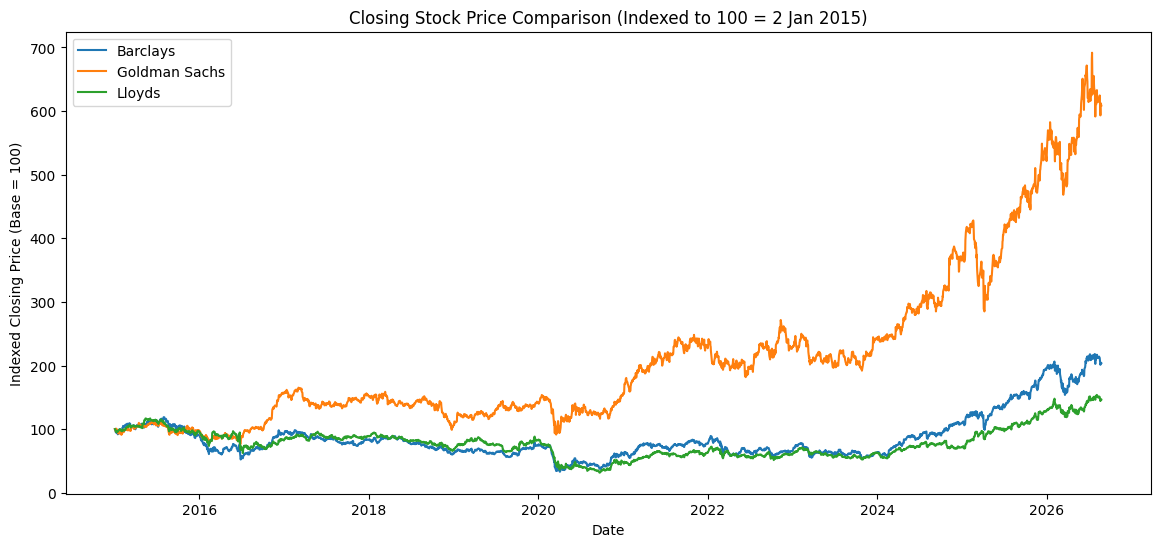

In [42]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14,6))

for bank in df['Bank'].unique():

    temp = df[df['Bank'] == bank].sort_values('Date')

    indexed = (temp['Close_GBX'] / temp['Close_GBX'].iloc[0]) * 100

    plt.plot(
        temp['Date'],
        indexed,
        label=bank
    )

plt.title(
    'Closing Stock Price Comparison (Indexed to 100 = 2 Jan 2015)'
)
plt.xlabel('Date')
plt.ylabel('Indexed Closing Price (Base = 100)')
plt.legend()
plt.show()

## Trading Volume

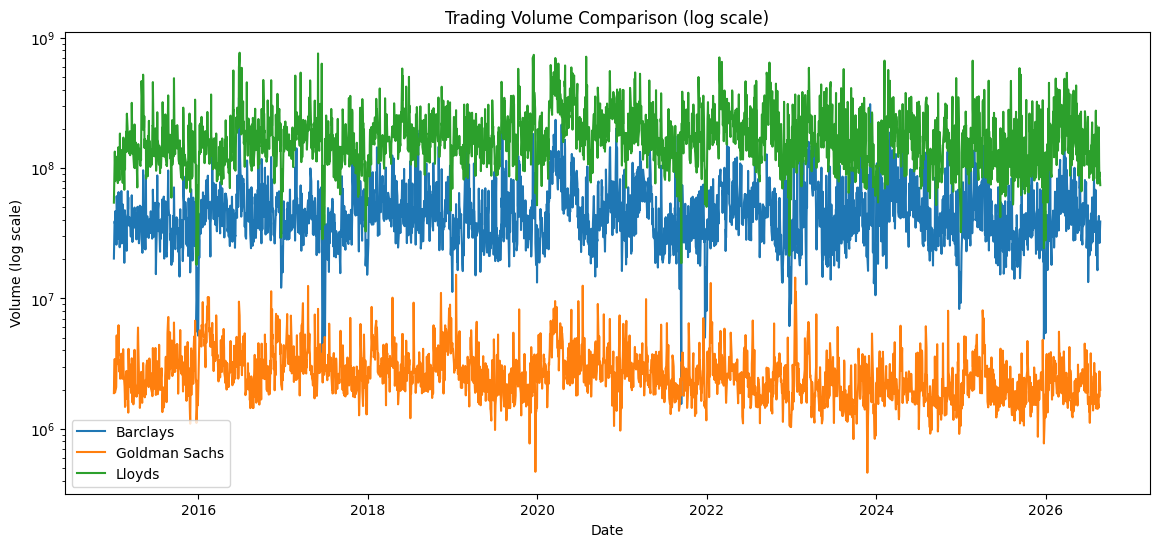

In [43]:
plt.figure(figsize=(14,6))

for bank in df['Bank'].unique():

    temp = df[df['Bank'] == bank]

    plt.plot(
        temp['Date'],
        temp['Volume'],
        label=bank
    )

plt.yscale('log')
plt.title(
    'Trading Volume Comparison (log scale)'
)
plt.xlabel('Date')
plt.ylabel('Volume (log scale)')
plt.legend()
plt.show()

## Distribution of Closing Prices

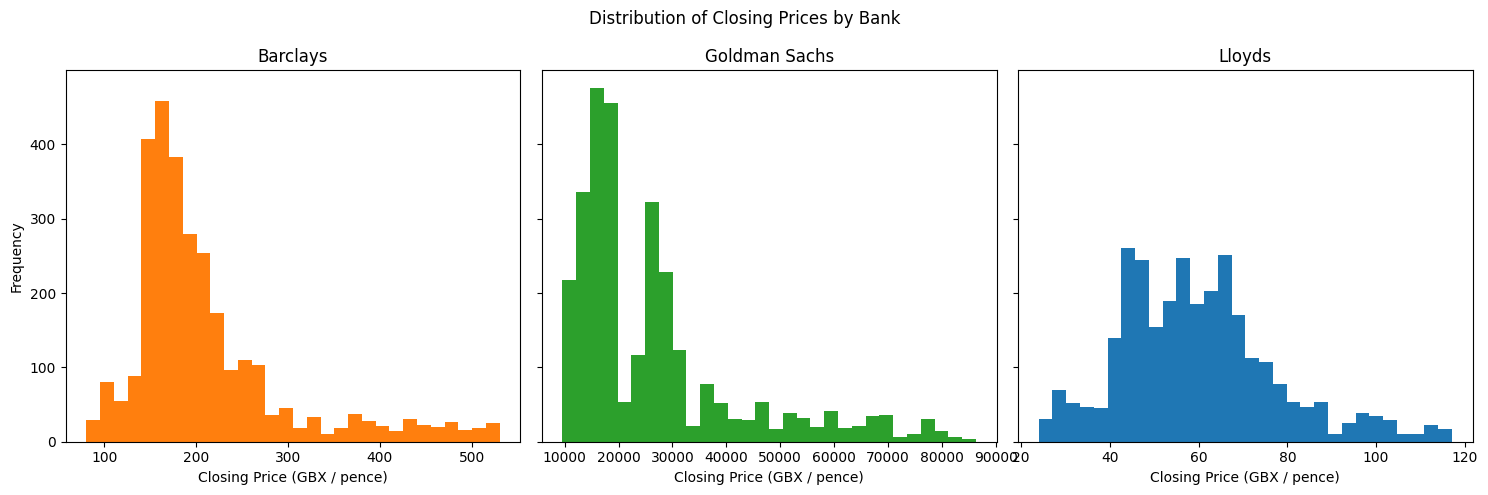

In [44]:
banks = df['Bank'].unique()

fig, axes = plt.subplots(1, len(banks), figsize=(15, 5), sharey=True)

colors = {'Lloyds': 'tab:blue', 'Barclays': 'tab:orange', 'Goldman Sachs': 'tab:green'}

for ax, bank in zip(axes, banks):

    temp = df[df['Bank'] == bank]

    ax.hist(
        temp['Close_GBX'],
        bins=30,
        color=colors.get(bank)
    )

    ax.set_title(bank)
    ax.set_xlabel('Closing Price (GBX / pence)')

axes[0].set_ylabel('Frequency')
fig.suptitle('Distribution of Closing Prices by Bank')
plt.tight_layout()
plt.show()


## Volatility Analysis

### Daily Returns

In [45]:
df = df.sort_values(
    ['Bank','Date']
)

df['Daily_Return'] = (
    df.groupby('Bank')['Close']
      .pct_change()
)

### Volatility Calculation

In [46]:
volatility = df.groupby(
    'Bank'
)['Daily_Return'].std()
print(volatility)

Bank
Barclays         0.021446
Goldman Sachs    0.018546
Lloyds           0.018973
Name: Daily_Return, dtype: float64


### Volatility Bar Chart

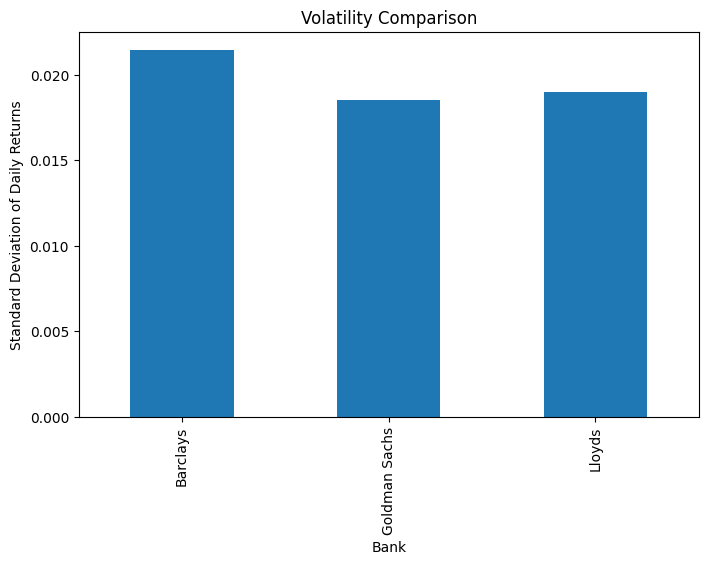

In [47]:
volatility.plot(
    kind='bar',
    figsize=(8,5)
)
plt.title(
    'Volatility Comparison'
)
plt.ylabel(
    'Standard Deviation of Daily Returns'
)
plt.show()